In [144]:
from collections import defaultdict
from pathlib import Path

import pandas as pd
from acteval.describe.frequency import frequency_plots, plot_agg_acts
from acteval.describe.times import joint_time_distributions_plot
from acteval.describe.transitions import sequence_prob_plot
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from plots import plot_b

In [145]:
cmap = {
    "home": (0.5529411764705883, 0.8274509803921568, 0.7803921568627451),
    "other": (1.0, 1.0, 0.7019607843137254),
    "shop": (0.7450980392156863, 0.7294117647058823, 0.8549019607843137),
    "work": (0.984313725490196, 0.5019607843137255, 0.4470588235294118),
    "escort": (0.5019607843137255, 0.6941176470588235, 0.8274509803921568),
    "visit": (0.9921568627450981, 0.7058823529411765, 0.3843137254901961),
    "education": (0.7019607843137254, 0.8705882352941177, 0.4117647058823529),
    "medical": (0.9882352941176471, 0.803921568627451, 0.8980392156862745),
    "travel": (0.8509803921568627, 0.8509803921568627, 0.8509803921568627),
    "leisure": (0.996078431372549, 0.8509803921568627, 0.6509803921568628),
}


def latest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[-1]


def earliest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[0]


def iter_models(path: Path):
    for dir in path.iterdir():

        if dir.is_dir():

            yield latest(dir)


def find_nth(path: Path, n=0):

    ranks = (
        pd.read_csv(path / "domain_distances.csv")
        .drop(columns=["domain", "observed", "mean", "std"], errors="ignore")
        .rank(axis=1, method="min")
        .sum(axis=0)
    )
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def best_quality(path: Path, n=0):

    data = pd.read_csv(path / "domain_distances.csv")
    data = data[data.domain == "sample quality"].drop(
        columns=["domain", "observed", "mean", "std"], errors="ignore"
    )
    ranks = data.rank(axis=1, method="min").sum(axis=0)
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def load_attributes(path: Path, default=None):
    if (path / "synthetic_attributes.csv").exists():
        print(f"Loading synthetic attributes from {path}")
        return pd.read_csv(path / "synthetic_attributes.csv")
    if (path / "synthetic_labels.csv").exists():
        print(f"Loading synthetic labels from {path}")
        return pd.read_csv(path / "synthetic_labels.csv")
    print(f"Failed to find attributes at {path}")
    return default


def split_on(schedules, attributes, by="work_status"):
    splits = attributes.groupby(by)
    return {
        k: schedules.loc[schedules.pid.isin(list(v.pid))]
        for k, v in splits
        if k != "unknown"
    }


def styler(df, vmin=-1, vmax=1):
    df = -df
    df.loc["24", "london"] = None
    df.loc["00-24", "london"] = None
    for yrs in ["24", "23-24"]:
        for source in ["west", "global"]:
            df.loc[yrs, source] = None

    styled = df.style.background_gradient(
        cmap="RdYlGn", vmin=vmin, vmax=vmax
    ).format("{:.1%}", na_rep="")

    return styled

In [146]:
training_data_route = Path("../../tmp/foundation/experiment")

target_schedules = pd.read_csv(training_data_route / "24_london_activities.csv")
target_attributes = pd.read_csv(
    training_data_route / "24_london_attributes.csv"
)

counts = defaultdict(list)
for yrs in ["24", "23-24", "20-24", "10-24", "00-24"]:
    for scope in ["uk", "europe", "west", "global"]:
        training_data_route = Path(
            f"../../tmp/foundation/experiment/{yrs}_{scope}_attributes.csv"
        )
        atts = pd.read_csv(training_data_route, usecols=[0]).shape[0]
        counts[yrs].append(atts)

counts = pd.DataFrame(counts, index=["uk", "europe", "west", "global"]).T
counts

,uk,europe,west,global
24,109547,170827,170827,170827
23-24,200755,318657,319398,319398
20-24,361360,589725,605034,725134
10-24,1403696,1728305,2001839,2121939
00-24,2483044,2807653,3464294,3584394


In [147]:
base = counts.iloc[0].iloc[0]
relative = (counts - base) / base
relative

,uk,europe,west,global
24,0.000000,0.559395,0.559395,0.559395
23-24,0.832592,1.908861,1.915625,1.915625
20-24,2.298675,4.383306,4.523054,5.619387
10-24,11.813642,14.776836,17.273791,18.370124
00-24,21.666472,24.629666,30.623814,31.720148


In [148]:
styler(-relative, vmin=-130, vmax=100)

,uk,europe,west,global,london
24,0.0%,55.9%,,,
23-24,83.3%,190.9%,,,
20-24,229.9%,438.3%,452.3%,561.9%,
10-24,1181.4%,1477.7%,1727.4%,1837.0%,
00-24,2166.6%,2463.0%,3062.4%,3172.0%,


In [149]:
training_data_route = Path("../../tmp/foundation/experiment")

training_schedules = {}
training_attributes = {}

counts = defaultdict(list)
for yrs in ["24", "23-24"]:
    for scope in ["uk", "europe", "west", "global"]:
        schedules_path = Path(
            f"../../tmp/foundation/experiment/{yrs}_{scope}_activities.csv"
        )
        attributes_path = Path(
            f"../../tmp/foundation/experiment/{yrs}_{scope}_attributes.csv"
        )
        training_schedules[f"{yrs}_{scope}"] = pd.read_csv(schedules_path)
        training_attributes[f"{yrs}_{scope}"] = pd.read_csv(attributes_path)

In [150]:
def freq_plotter(all_schedules, schedules, attributes):
    act_order = all_schedules.act.value_counts().index.to_list()
    class_map = {n: i for i, n in enumerate(act_order)}
    class_map["medical"] = len(class_map)
    class_map["visit"] = len(class_map)  # add unknown class
    print(f"Class map: {class_map}")

    FILTER = ["student", "employed", "unemployed", "retired"]
    NAMES = ["Student", "Employed", "Unemployed", "Retired"]

    h = len(schedules)
    w = len(FILTER)
    fig, axes = plt.subplots(
        h, w + 2, figsize=(w * 2.2, h * 2), sharex=False, sharey=False
    )

    for i, (name, scheds) in enumerate(schedules.items()):

        splits = split_on(scheds, attributes[name], by="employment")

        for j, f in enumerate(FILTER):
            axes[0, j].set_title(NAMES[j], fontsize=12)
            selected = splits.get(f)
            if selected is not None:
                ax = plot_agg_acts(
                    "",
                    selected,
                    class_map=class_map,
                    ax=axes[i, j],
                    legend=False,
                    color=cmap,
                )
            else:
                ax = axes[i, j]
            ax.set_title(None)
            ax.set_ylabel(None)
            ax.set_xlabel(None)
            ax.set_yticks([])
            ax.set_xticks([])

            axes[-1, j].set_xticks(
                [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
                labels=[
                    "",
                    "04:00",
                    "08:00",
                    "12:00",
                    "16:00",
                    "20:00",
                    "24:00",
                ],
                rotation=90,
                fontsize=8,
            )

        axes[0, -2].set_title("Combined", fontsize=12)
        ax = plot_agg_acts(
            "",
            scheds,
            class_map=class_map,
            ax=axes[i, -2],
            legend=False,
            color=cmap,
        )
        ax.set_title(None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.set_yticks([])
        ax.set_xticks([])

        axes[-1, -2].set_xticks(
            [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
            labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
            rotation=90,
            fontsize=8,
        )

        axes[i, 0].set_ylabel(name, fontsize=12)
        axes[i, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        axes[i, 0].set_yticklabels(
            ["", "20% ", "40% ", "60% ", "80% ", "100%"],
            rotation=90,
            fontsize=8,
        )

        axes[i, -1].axis("off")

    elements = [
        Patch(facecolor=cmap[act], label=act.title()) for act in act_order
    ]
    axes[0, -1].axis("off")
    axes[0, -1].legend(handles=elements, loc="center left", frameon=False)

    plt.subplots_adjust(wspace=0.04, hspace=0.05)

Class map: {'home': 0, 'leisure': 1, 'shop': 2, 'work': 3, 'education': 4, 'other': 5, 'escort': 6, 'medical': 7, 'visit': 8}


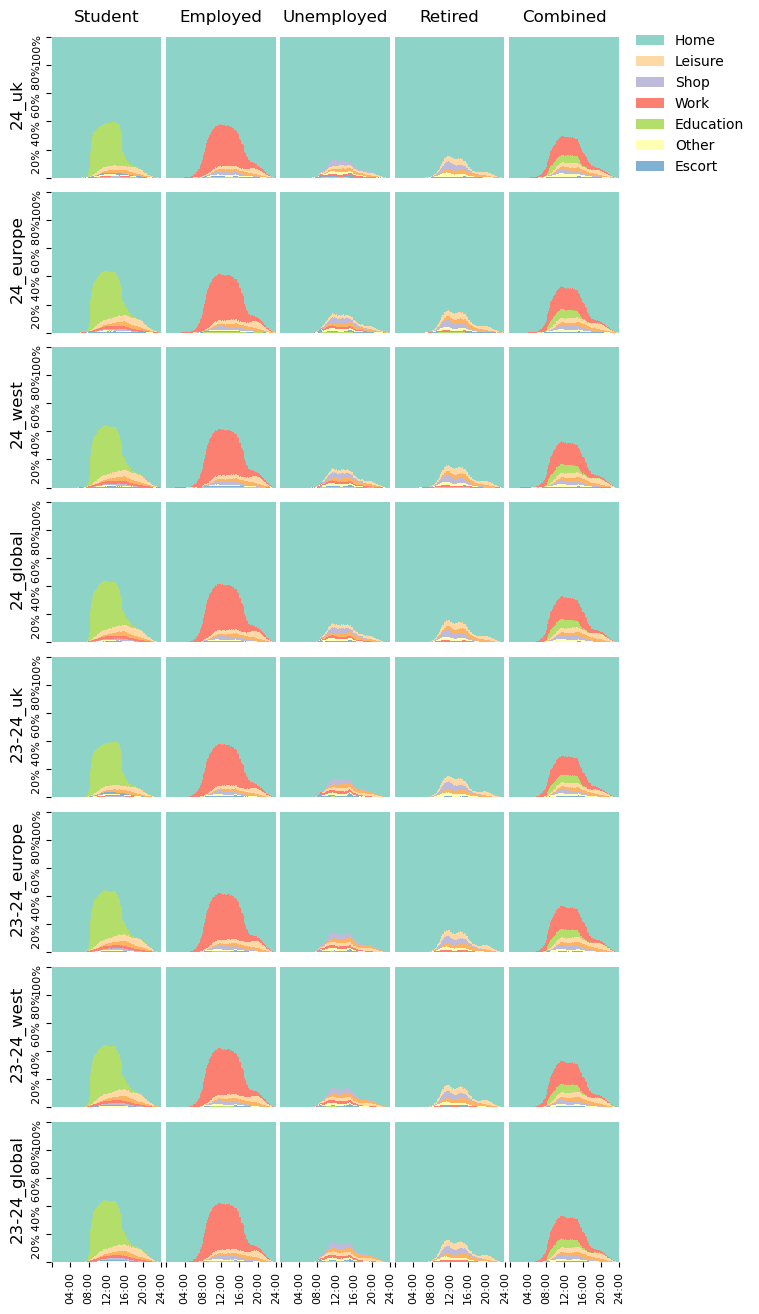

In [151]:
freq_plotter(target_schedules, training_schedules, training_attributes)

In [152]:
training_data_route = Path("../../tmp/foundation/experiment")
all_schedules = pd.read_csv(training_data_route / "00-24_global_activities.csv")
all_attributes = pd.read_csv(
    training_data_route / "00-24_global_attributes.csv"
)

/tmp/ipykernel_128698/1487252258.py:3: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  all_attributes = pd.read_csv(


In [153]:
all_attributes.columns

Index(['hid', 'pid', 'age', 'hh_size', 'hh_income', 'sex', 'dwelling',
       'ownership', 'vehicles', 'disability', 'education', 'can_wfh',
       'occupation', 'race', 'has_licence', 'relationship', 'employment',
       'employed_type', 'country', 'source', 'year', 'month', 'day', 'hh_zone',
       'weight', 'access_egress_distance', 'max_temp_c', 'rain', 'avg_speed'],
      dtype='object')

In [154]:
result_matrix = pd.crosstab(
    [all_attributes["source"], all_attributes["year"]],
    all_attributes["employment"],
    normalize="index",
)
# set to null if 0
result_matrix[result_matrix == 0] = None
result_matrix.style.background_gradient(
    cmap="RdYlGn", vmin=0, vmax=result_matrix.max().max()
).format("{:.1%}", na_rep="")

In [155]:
all_attributes.columns

Index(['hid', 'pid', 'age', 'hh_size', 'hh_income', 'sex', 'dwelling',
       'ownership', 'vehicles', 'disability', 'education', 'can_wfh',
       'occupation', 'race', 'has_licence', 'relationship', 'employment',
       'employed_type', 'country', 'source', 'year', 'month', 'day', 'hh_zone',
       'weight', 'access_egress_distance', 'max_temp_c', 'rain', 'avg_speed'],
      dtype='object')

In [156]:
result_matrix = pd.crosstab(
    [all_attributes["source"], all_attributes["year"]],
    all_attributes["hh_income"],
    normalize="index",
)
# set to null if 0
result_matrix[result_matrix == 0] = None
result_matrix.style.background_gradient(
    cmap="RdYlGn", vmin=0, vmax=result_matrix.max().max()
).format("{:.1%}", na_rep="")

In [157]:
raw_attributes = pd.read_csv(Path("../../../foundata/output/attributes.csv"))

# select only qhts data for 2019 and 2020
raw_attributes[(raw_attributes.source == "cmap")][
    (raw_attributes.year.isin([2017, 2018, 2019, 2020]))
].education.value_counts()

/tmp/ipykernel_128698/39643766.py:1: DtypeWarning: Columns (6,7,9,10,11,12,13,15,27) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_attributes = pd.read_csv(Path("../../../foundata/output/attributes.csv"))
/tmp/ipykernel_128698/39643766.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  raw_attributes[(raw_attributes.source == "cmap")][


education
degree         12316
school          7296
high-school     6069
Name: count, dtype: int64

In [159]:
sourced_schedules = {}
sourced_attributes = {}

counts = defaultdict(list)
for yrs in ["20-24"]:
    for scope in [
        "london",
        "uk",
        "dutch",
        "us",
        "chicago",
        "victoria",
        "queensland",
        "korea",
    ]:
        schedules_path = Path(
            f"../../tmp/foundation/sources/{yrs}_{scope}_activities.csv"
        )
        attributes_path = Path(
            f"../../tmp/foundation/sources/{yrs}_{scope}_attributes.csv"
        )
        sourced_schedules[f"{yrs}_{scope}"] = pd.read_csv(schedules_path)
        sourced_attributes[f"{yrs}_{scope}"] = pd.read_csv(attributes_path)

/tmp/ipykernel_128698/1651172292.py:23: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  sourced_attributes[f"{yrs}_{scope}"] = pd.read_csv(attributes_path)


In [160]:
for name, attr in sourced_attributes.items():
    print(f"{name}: {attr.shape[0]} attributes")
    print(attr["employment"].value_counts())
    print()

20-24_london: 0 attributes
Series([], Name: count, dtype: int64)

20-24_uk: 361360 attributes
employment
employed      163392
retired       105398
unknown        62166
other          15322
student        11191
unemployed      3891
Name: count, dtype: int64

20-24_dutch: 228365 attributes
employment
employed      109850
retired        51168
student        39027
unemployed     15501
other          12819
Name: count, dtype: int64

20-24_us: 15309 attributes
employment
employed      6893
retired       3689
void          2019
unemployed    1193
other         1025
student        490
Name: count, dtype: int64

20-24_chicago: 0 attributes
Series([], Name: count, dtype: int64)

20-24_victoria: 16515 attributes
employment
employed      7578
student       3196
retired       2868
other         2336
unemployed     537
Name: count, dtype: int64

20-24_queensland: 38824 attributes
employment
employed      18670
retired        8115
student        7799
other          2252
unemployed     1948
void      

Class map: {'home': 0, 'leisure': 1, 'shop': 2, 'work': 3, 'education': 4, 'other': 5, 'escort': 6, 'medical': 7, 'visit': 8}


/home/fred/Projects/acteval/src/acteval/features/frequency.py:26: RuntimeWarning: Mean of empty slice.
  ).mean(0)[0, :, :]
/home/fred/miniforge3/envs/caveat/lib/python3.12/site-packages/numpy/_core/_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/home/fred/Projects/acteval/src/acteval/features/frequency.py:26: RuntimeWarning: Mean of empty slice.
  ).mean(0)[0, :, :]
/home/fred/miniforge3/envs/caveat/lib/python3.12/site-packages/numpy/_core/_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


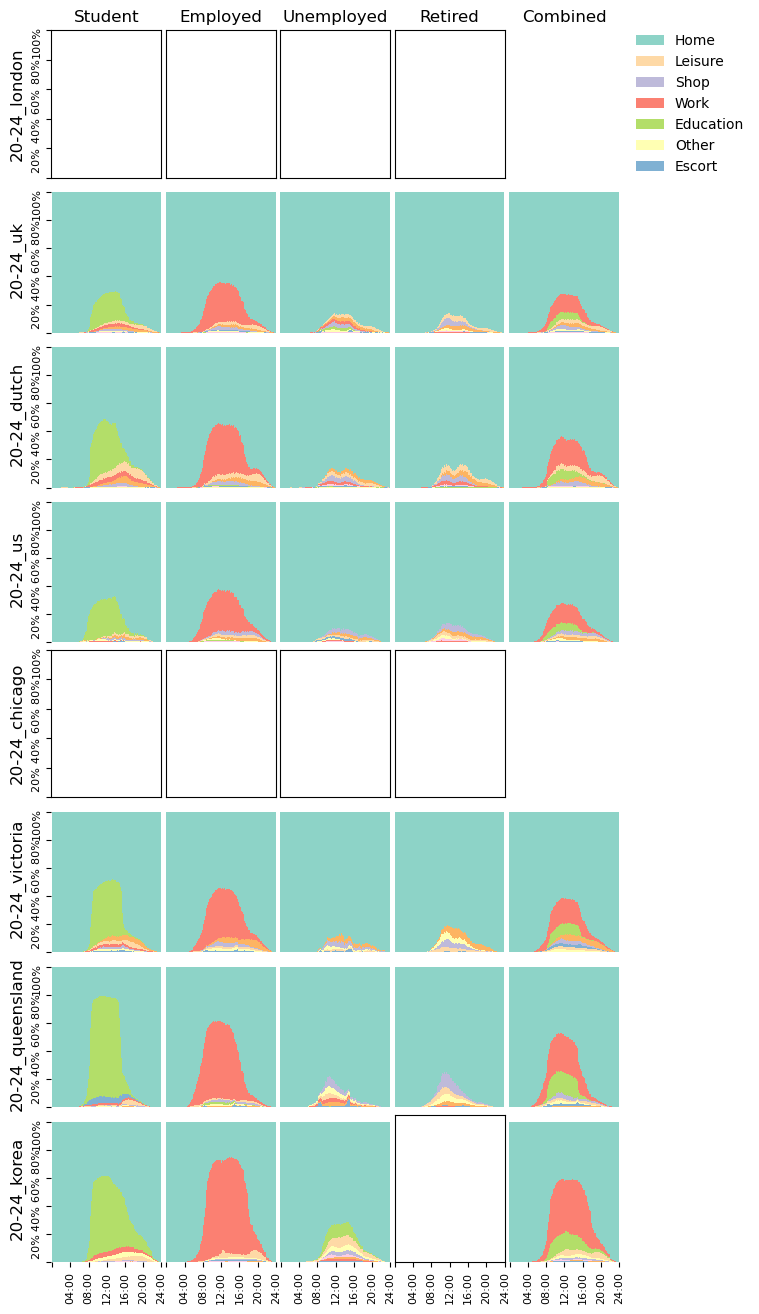

In [161]:
freq_plotter(target_schedules, sourced_schedules, sourced_attributes)

In [175]:
outpath = Path("../../logs/foundations/experiment_uk")
domains = pd.read_csv(outpath / "eval" / "domains" / "distances.csv").set_index(
    "domain"
)
cols = domains.columns
cols = ["24_uk"] + [c for c in cols]

domains = domains[cols]
domains

,24_uk,24_uk,24_europe,24_west,24_global,23-24_uk,23-24_europe,23-24_west,23-24_global,20-24_uk,...,20-24_west,20-24_global,10-24_uk,10-24_europe,10-24_west,10-24_global,00-24_uk,00-24_europe,00-24_west,00-24_global
domain,,,,,,,,,,,,,,,,,,,,,
creativity,0.222141,0.222141,0.187184,0.187184,0.187184,0.212228,0.228441,0.227508,0.227508,0.235196,...,0.219065,0.221759,0.217055,0.227566,0.218646,0.217803,0.221264,0.222135,0.227045,0.209701
feasibility,0.010425,0.010425,0.006399,0.006399,0.006399,0.008371,0.005724,0.005075,0.005075,0.015281,...,0.011867,0.008964,0.007604,0.004007,0.009923,0.007750,0.005614,0.005431,0.004729,0.008517
participations,0.043104,0.043104,0.061800,0.061800,0.061800,0.034010,0.052769,0.045158,0.045158,0.060212,...,0.038460,0.036625,0.025522,0.059853,0.037992,0.022896,0.034729,0.030265,0.038342,0.028788
timing,0.029975,0.029975,0.029534,0.029534,0.029534,0.031694,0.028663,0.024227,0.024227,0.029107,...,0.028093,0.025060,0.018327,0.028845,0.023256,0.019716,0.021903,0.022112,0.022829,0.020589
transitions,0.003387,0.003387,0.003804,0.003804,0.003804,0.004275,0.003322,0.002710,0.002710,0.003535,...,0.003714,0.003403,0.003028,0.003379,0.003901,0.003021,0.003030,0.002453,0.003303,0.003716


In [176]:
baseline = domains.iloc[:, 0]
baseline

domain
creativity        0.222141
feasibility       0.010425
participations    0.043104
timing            0.029975
transitions       0.003387
Name: 24_uk, dtype: float64

In [177]:
# drop the first column and keep the rest
relative = domains.iloc[:, 1:]

# subtract the baseline column from all columns to get distances
relative = relative.sub(baseline, axis=0)

# # divide each column by the first column to get relative distances
relative = relative.div(baseline, axis=0)

sum_relative = relative.sum(axis=0)
sum_relative

24_uk           0.000000
24_europe      -0.001357
24_west        -0.001357
24_global      -0.001357
23-24_uk       -0.133097
23-24_europe   -0.261434
23-24_west     -0.832971
23-24_global   -0.832971
20-24_uk        0.936157
20-24_europe   -0.387835
20-24_west      0.050470
20-24_global   -0.451338
10-24_uk       -1.195996
10-24_europe   -0.242592
10-24_west     -0.254858
10-24_global   -1.195272
00-24_uk       -1.034283
00-24_europe   -1.314956
00-24_west     -0.897956
00-24_global   -0.787079
dtype: float64

In [185]:
def unpack_scores(data: pd.Series) -> pd.DataFrame:
    scores = defaultdict(list)
    for yrs in ["24", "23-24", "20-24", "10-24", "00-24"]:
        for scope in ["uk", "europe", "west", "global"]:
            score = data[f"{yrs}_{scope}"]
            scores[yrs].append(score)
    scores = pd.DataFrame(scores, index=["uk", "europe", "west", "global"]).T
    return scores


unpack_scores(sum_relative)

,uk,europe,west,global
24,0.000000,-0.001357,-0.001357,-0.001357
23-24,-0.133097,-0.261434,-0.832971,-0.832971
20-24,0.936157,-0.387835,0.050470,-0.451338
10-24,-1.195996,-0.242592,-0.254858,-1.195272
00-24,-1.034283,-1.314956,-0.897956,-0.787079


In [186]:
relative.loc["creativity"]

24_uk           0.000000
24_europe      -0.157365
24_west        -0.157365
24_global      -0.157365
23-24_uk       -0.044627
23-24_europe    0.028358
23-24_west      0.024157
23-24_global    0.024157
20-24_uk        0.058767
20-24_europe    0.005642
20-24_west     -0.013849
20-24_global   -0.001723
10-24_uk       -0.022897
10-24_europe    0.024418
10-24_west     -0.015734
10-24_global   -0.019529
00-24_uk       -0.003949
00-24_europe   -0.000029
00-24_west      0.022073
00-24_global   -0.056001
Name: creativity, dtype: float64

In [187]:
domain_scores = defaultdict(list)

for domain in domains.index:
    domain_scores[domain] = unpack_scores(relative.loc[domain])


def styler(df):
    df = -df
    # df.loc["24", "london"] = None
    # df.loc["00-24", "london"] = None
    for yrs in ["24", "23-24"]:
        for source in ["west", "global"]:
            df.loc[yrs, source] = None

    styled = df.style.background_gradient(
        cmap="RdYlGn", vmin=-1, vmax=1
    ).format("{:.1%}", na_rep="")

    return styled


styler(domain_scores["creativity"])

,uk,europe,west,global
24,-0.0%,15.7%,,
23-24,4.5%,-2.8%,,
20-24,-5.9%,-0.6%,1.4%,0.2%
10-24,2.3%,-2.4%,1.6%,2.0%
00-24,0.4%,0.0%,-2.2%,5.6%


In [188]:
styler(domain_scores["feasibility"])

,uk,europe,west,global
24,-0.0%,38.6%,,
23-24,19.7%,45.1%,,
20-24,-46.6%,-0.5%,-13.8%,14.0%
10-24,27.1%,61.6%,4.8%,25.7%
00-24,46.1%,47.9%,54.6%,18.3%


In [189]:
styler(domain_scores["participations"])

,uk,europe,west,global
24,-0.0%,-43.4%,,
23-24,21.1%,-22.4%,,
20-24,-39.7%,12.2%,10.8%,15.0%
10-24,40.8%,-38.9%,11.9%,46.9%
00-24,19.4%,29.8%,11.0%,33.2%


In [190]:
styler(domain_scores["transitions"])

,uk,europe,west,global
24,-0.0%,-12.3%,,
23-24,-26.2%,1.9%,,
20-24,-4.4%,8.1%,-9.6%,-0.5%
10-24,10.6%,0.2%,-15.2%,10.8%
00-24,10.5%,27.6%,2.5%,-9.7%


In [191]:
styler(domain_scores["timing"])

,uk,europe,west,global
24,-0.0%,1.5%,,
23-24,-5.7%,4.4%,,
20-24,2.9%,19.7%,6.3%,16.4%
10-24,38.9%,3.8%,22.4%,34.2%
00-24,26.9%,26.2%,23.8%,31.3%


In [172]:
data_route = Path("../../logs/foundations/experiment_uk")
batch_paths = {}
for yrs in ["24", "23-24", "20-24", "10-24"]:
    for scope in ["uk", "europe", "west", "global"]:
        name = f"{yrs}_{scope}"
        # if name in ["00-24_west", "00-24_global"]:
        #     continue
        batch_paths[name] = data_route / name

schedules = {
    n: pd.read_csv(latest(p)[1] / "synthetic_schedules.csv")
    for n, p in batch_paths.items()
}
attributes = {
    n: load_attributes(latest(p)[1], default=target_attributes)
    for n, p in batch_paths.items()
}

Found versions for 24_uk: ['version_0', 'version_1', 'version_2', 'version_3', 'version_4', 'version_5', 'version_6', 'version_7']. Returning ../../logs/foundations/experiment_uk/24_uk/version_7
Found versions for 24_europe: ['version_0', 'version_1', 'version_2', 'version_3', 'version_4', 'version_5', 'version_6']. Returning ../../logs/foundations/experiment_uk/24_europe/version_6
Found versions for 24_west: ['version_0', 'version_1', 'version_2', 'version_3', 'version_4', 'version_5']. Returning ../../logs/foundations/experiment_uk/24_west/version_5
Found versions for 24_global: ['version_0', 'version_1', 'version_2', 'version_3', 'version_4', 'version_5']. Returning ../../logs/foundations/experiment_uk/24_global/version_5
Found versions for 23-24_uk: ['version_0', 'version_1', 'version_2', 'version_3', 'version_4']. Returning ../../logs/foundations/experiment_uk/23-24_uk/version_4
Found versions for 23-24_europe: ['version_0', 'version_1', 'version_2', 'version_3', 'version_4']. Ret

Class map: {'home': 0, 'shop': 1, 'work': 2, 'leisure': 3, 'escort': 4, 'visit': 5, 'other': 6, 'education': 7}


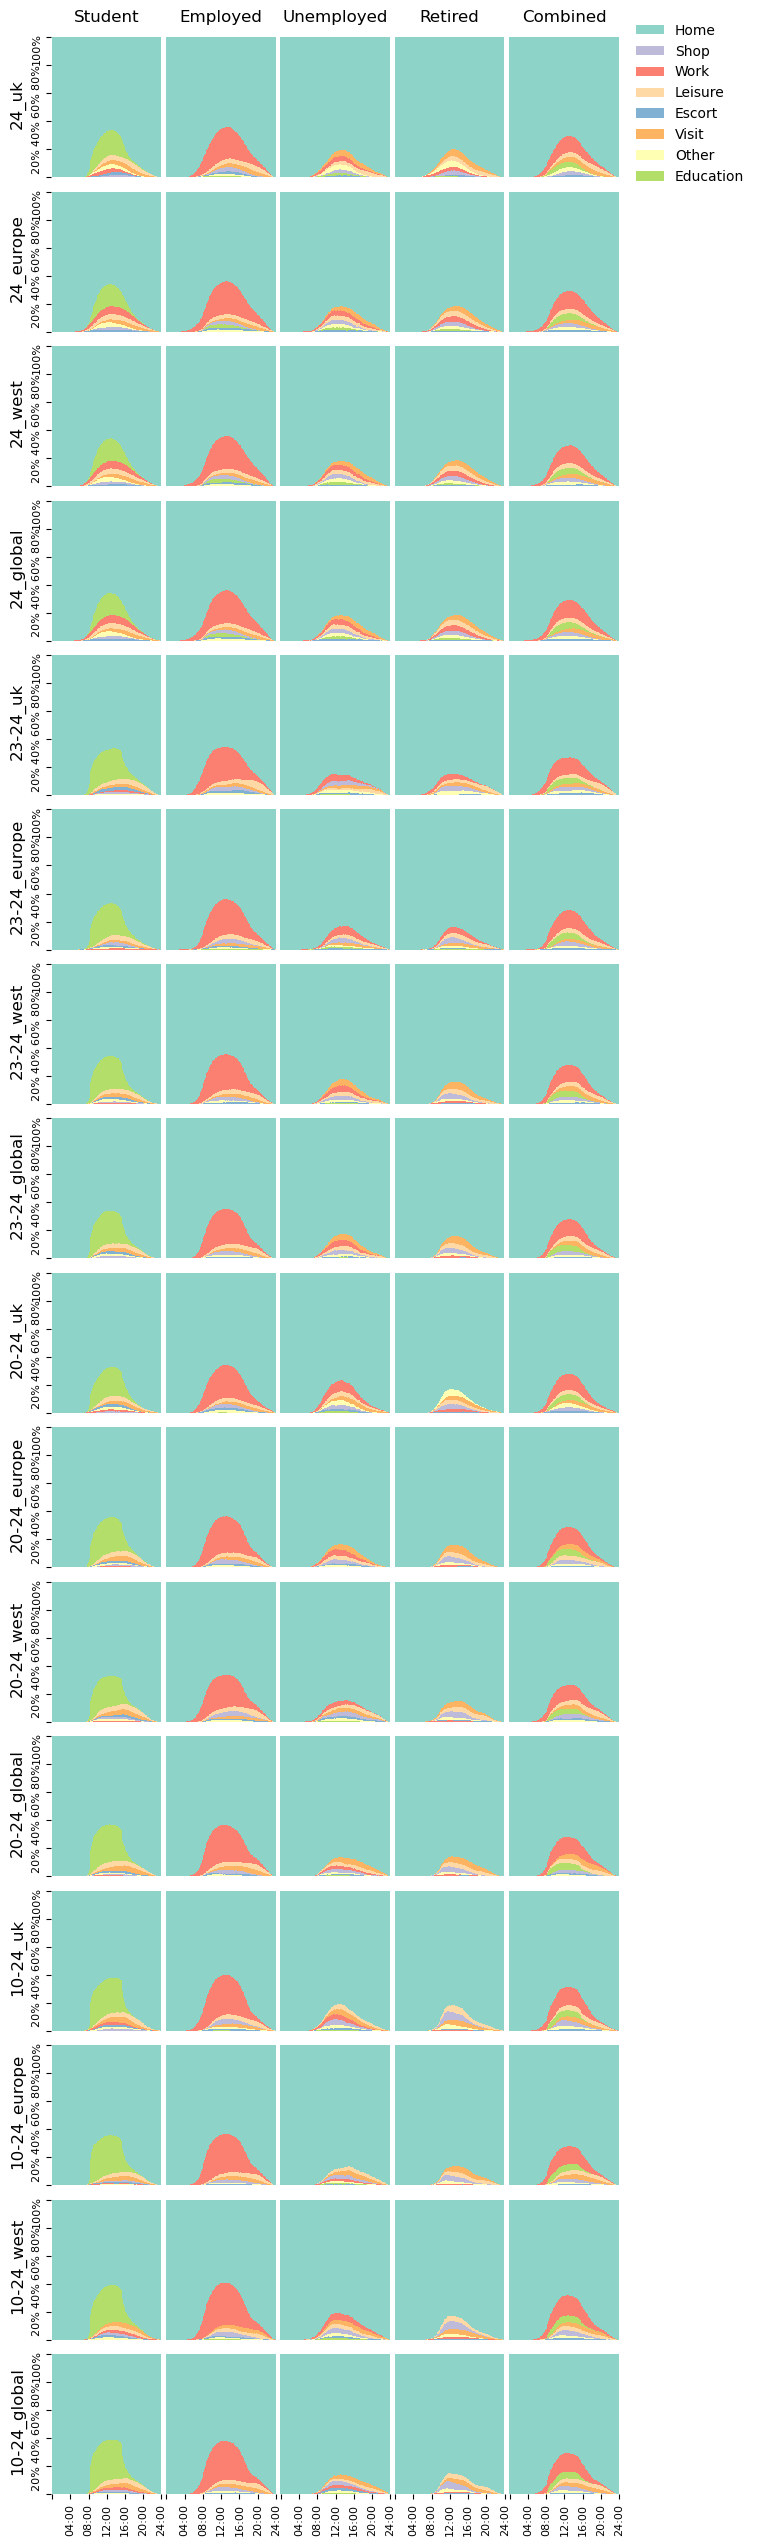

In [173]:
act_order = schedules["10-24_europe"].act.value_counts().index.to_list()
class_map = {n: i for i, n in enumerate(act_order)}
print(f"Class map: {class_map}")

FILTER = ["student", "employed", "unemployed", "retired"]
NAMES = ["Student", "Employed", "Unemployed", "Retired"]

h = len(schedules)
w = len(FILTER)
fig, axes = plt.subplots(
    h, w + 2, figsize=(w * 2.2, h * 2), sharex=False, sharey=False
)

for i, (name, scheds) in enumerate(schedules.items()):

    splits = split_on(scheds, attributes[name], by="employment")

    for j, f in enumerate(FILTER):
        axes[0, j].set_title(NAMES[j], fontsize=12)
        selected = splits[f]
        ax = plot_agg_acts(
            "",
            selected,
            class_map=class_map,
            ax=axes[i, j],
            legend=False,
            color=cmap,
        )
        ax.set_title(None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.set_yticks([])
        ax.set_xticks([])

        axes[-1, j].set_xticks(
            [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
            labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
            rotation=90,
            fontsize=8,
        )

    axes[0, -2].set_title("Combined", fontsize=12)
    ax = plot_agg_acts(
        "",
        scheds,
        class_map=class_map,
        ax=axes[i, -2],
        legend=False,
        color=cmap,
    )
    ax.set_title(None)
    ax.set_ylabel(None)
    ax.set_xlabel(None)
    ax.set_yticks([])
    ax.set_xticks([])

    axes[-1, -2].set_xticks(
        [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
        labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
        rotation=90,
        fontsize=8,
    )

    axes[i, 0].set_ylabel(name, fontsize=12)
    axes[i, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    axes[i, 0].set_yticklabels(
        ["", "20% ", "40% ", "60% ", "80% ", "100%"], rotation=90, fontsize=8
    )

    axes[i, -1].axis("off")

elements = [Patch(facecolor=cmap[act], label=act.title()) for act in act_order]
axes[0, -1].axis("off")
axes[0, -1].legend(handles=elements, loc="center left", frameon=False)

plt.subplots_adjust(wspace=0.04, hspace=0.05)

In [174]:
training_schedules = {}
training_attributes = {}
for yrs in ["24", "23-24", "20-24"]:
    for scope in ["uk", "europe", "west", "global"]:
        training_data_route = Path("../../tmp/foundation/experiment_uk")
        training_schedules[f"{yrs}_{scope}"] = pd.read_csv(
            training_data_route / f"{yrs}_{scope}_activities.csv",
            low_memory=False,
        )
        training_attributes[f"{yrs}_{scope}"] = pd.read_csv(
            training_data_route / f"{yrs}_{scope}_attributes.csv",
            low_memory=False,
        )

FileNotFoundError: [Errno 2] No such file or directory: '../../tmp/foundation/experiment_uk/24_uk_activities.csv'

In [ ]:
from acteval.describe.frequency import frequency_plots
from acteval.describe.times import joint_time_distributions_plot
from acteval.describe.transitions import sequence_prob_plot

target = training_schedules.pop("24_london")

f = joint_time_distributions_plot(
    observed=target, ys=training_schedules, cmap=cmap, figsize=(12, 12)
)
f = frequency_plots(
    observed=target, ys=training_schedules, cmap=cmap, figsize=(12, 6)
)
f = sequence_prob_plot(
    observed=target, ys=training_schedules, cmap=cmap, figsize=(12, 6)
)

KeyError: '24_london'

In [ ]:
# training_attributes = {
#     "uk": pd.read_csv(training_data_route / "uk_attributes.csv"),
#     "uk+aus": pd.read_csv(training_data_route / "uk+aus_attributes.csv"),
#     "western": pd.read_csv(training_data_route / "west_attributes.csv"),
#     "world": pd.read_csv(training_data_route / "world_attributes.csv"),
# }

# training_schedules = {
#     "uk": pd.read_csv(training_data_route / "uk_activities.csv"),
#     "uk+aus": pd.read_csv(training_data_route / "uk+aus_activities.csv"),
#     "western": pd.read_csv(training_data_route / "west_activities.csv"),
#     "world": pd.read_csv(training_data_route / "world_activities.csv"),
# }

In [ ]:
counter = {}
# load each and get counts per source
counter["baseline"] = target_attributes.source.value_counts()
for name, data in training_attributes.items():
    print(data.source.unique())
    counter[name] = data.source.value_counts()
df = pd.DataFrame(counter)


order = ["ktdb", "ltds", "vista", "qhts", "nhts", "nts"]
df = df.loc[order].fillna(0)
totals = df.sum()
totals_row = pd.DataFrame([totals], index=["Total"])
df = pd.concat([df, totals_row])
print(df.to_latex(float_format="{:.0f}".format))

In [ ]:
def distance_table(batch_path, suffix=""):
    df = pd.read_csv(batch_path / f"domain_distances{suffix}.csv").set_index(
        "domain"
    )
    order = [
        "participations",
        "transitions",
        "timing",
        "feasibility",
        "creativity",
    ]
    print(df.loc[order].to_latex(float_format="{:.3f}".format))
    return df.loc[order]


df = distance_table(Path("../../logs/foundations/B"), suffix="")

df

In [ ]:
df_alt = distance_table(Path("../../logs/foundations/B_alt"), suffix="")
diff = 100 * (df - df_alt) / df_alt
order = ["participations", "transitions", "timing", "feasibility", "creativity"]
print(diff.loc[order].to_latex(float_format="{:.1f}\%".format))
diff

In [ ]:
# _ = plot_b(
#     training_schedules, training_attributes, target_schedules, target_attributes
# )

In [ ]:
batch_root = Path("../../logs/foundations/B")

batch_paths = {
    "B0 (baseline)": batch_root / "baseline",
    "B1 (UK)": batch_root / "uk",
    "B2 (UK+AUS)": batch_root / "uk+aus",
    "B3 (West)": batch_root / "west",
    "B4 (World)": batch_root / "world",
}

# find data
data_root = Path("../../tmp/foundation")
target_schedules = pd.read_csv(
    data_root / "experiment_b" / "nts_activities_2024.csv"
)
acts = list(target_schedules.act.value_counts(ascending=False).index)
class_map = {n: i for i, n in enumerate(acts)}

target_attributes = pd.read_csv(
    data_root / "experiment_b" / "nts_attributes_2024.csv"
)

schedules = {
    n: pd.read_csv(latest(p)[1] / "synthetic_schedules.csv")
    for n, p in batch_paths.items()
}
attributes = {
    n: load_attributes(latest(p)[1], default=target_attributes)
    for n, p in batch_paths.items()
}
print(schedules.keys())
print(attributes.keys())

In [ ]:
_ = plot_b(schedules, attributes, target_schedules, target_attributes)